In [4]:
import os
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.manifold import MDS

from scipy.spatial.distance import squareform

In [5]:
results_folder = "../results"

participant_ids = []
participant_matrices = []

for folder in sorted(os.listdir(results_folder)):

    folder_path = os.path.join(results_folder, folder)

    if not os.path.isdir(folder_path):
        continue

    matrix_path = os.path.join(folder_path, f"{folder}_matrix.csv")

    if os.path.exists(matrix_path):

        matrix = pd.read_csv(matrix_path)

        participant_ids.append(folder)
        participant_matrices.append(matrix.values)

print("Participants loaded:", len(participant_matrices))

Participants loaded: 5


In [6]:
missing_summary = []

for pid, matrix in zip(participant_ids, participant_matrices):

    n_missing = np.isnan(matrix).sum()

    missing_summary.append([pid, n_missing])

missing_df = pd.DataFrame(
    missing_summary,
    columns=["Participant", "Missing Values"]
)

print(missing_df)

  Participant  Missing Values
0    CDT_P001              34
1    CDT_P002               2
2    CDT_P003               4
3    CDT_P004               5
4    CDT_P005               0


In [7]:
save_folder = "Individual_Heatmaps"

os.makedirs(save_folder, exist_ok=True)

for pid, matrix in zip(participant_ids, participant_matrices):

    plt.figure(figsize=(7,6))

    plt.imshow(matrix,
               cmap="viridis",
               vmin=0,
               vmax=1)

    plt.colorbar(label="Similarity")

    plt.title(pid)

    plt.xlabel("Stimulus")

    plt.ylabel("Stimulus")

    plt.tight_layout()

    plt.savefig(f"{save_folder}/{pid}_heatmap.png",
                dpi=300)

    plt.close()

In [8]:
group_similarity = np.nanmean(
    participant_matrices,
    axis=0
)

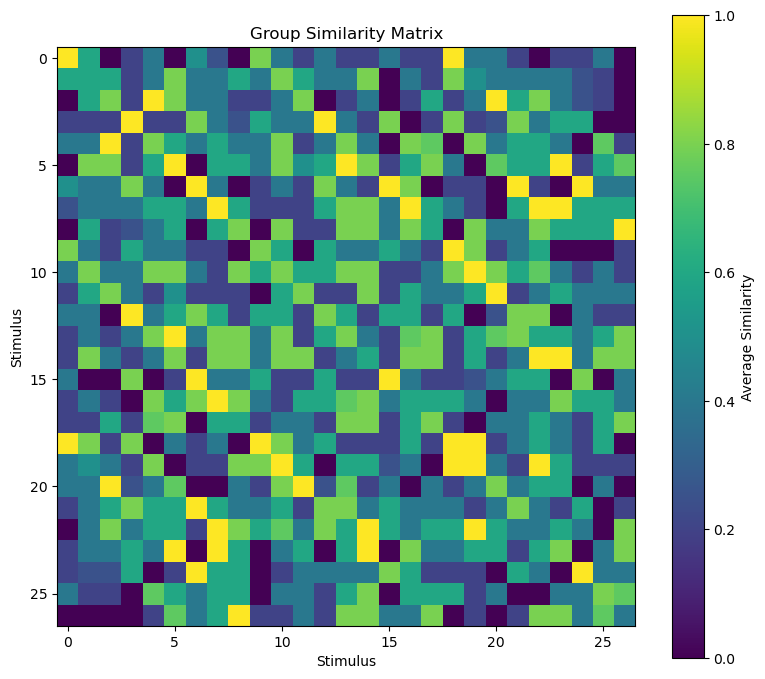

In [9]:
plt.figure(figsize=(8,7))

plt.imshow(group_similarity,
           cmap="viridis",
           vmin=0,
           vmax=1)

plt.colorbar(label="Average Similarity")

plt.title("Group Similarity Matrix")

plt.xlabel("Stimulus")

plt.ylabel("Stimulus")

plt.tight_layout()

plt.show()

In [10]:
filled_matrices = []

for matrix in participant_matrices:

    filled = matrix.copy()

    mask = np.isnan(filled)

    filled[mask] = group_similarity[mask]

    filled_matrices.append(filled)

In [11]:
dissimilarity_matrices = []

for matrix in filled_matrices:

    dissimilarity = 1 - matrix

    # Ensure self-distance is zero for MDS
    np.fill_diagonal(dissimilarity, 0)

    dissimilarity_matrices.append(dissimilarity)

In [12]:
mds = MDS(
    n_components=2,
    dissimilarity="precomputed",
    random_state=42,
    normalized_stress="auto"
)

participant_coordinates = []
participant_stress = []

for matrix in dissimilarity_matrices:

    coords = mds.fit_transform(matrix)

    participant_coordinates.append(coords)

    participant_stress.append(mds.stress_)

/opt/anaconda3/envs/vibrotactile/lib/python3.11/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/opt/anaconda3/envs/vibrotactile/lib/python3.11/site-packages/sklearn/manifold/_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(
/opt/anaconda3/envs/vibrotactile/lib/python3.11/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/opt/anaconda3/envs/vibrotactile/lib/python3.11/site-packages/sklearn/manifold/_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(
/opt/anaconda3/envs/vibrotactile/lib/p

In [13]:
stress_df = pd.DataFrame({
    "Participant": participant_ids,
    "Stress": participant_stress
})

print(stress_df)

print("\nMean Stress:", stress_df["Stress"].mean())
print("SD:", stress_df["Stress"].std())

  Participant     Stress
0    CDT_P001  53.987141
1    CDT_P002  57.973459
2    CDT_P003  65.141481
3    CDT_P004  67.432309
4    CDT_P005  28.832396

Mean Stress: 54.67335701578429
SD: 15.423110194836509


In [14]:
save_folder = "Individual_MDS"

os.makedirs(save_folder, exist_ok=True)

for pid, coords, stress in zip(
        participant_ids,
        participant_coordinates,
        participant_stress):

    plt.figure(figsize=(7,7))

    plt.scatter(coords[:,0],
                coords[:,1],
                s=60)

    for i in range(27):

        plt.text(
            coords[i,0],
            coords[i,1],
            str(i+1),
            fontsize=8
        )

    plt.title(f"{pid}\nStress = {stress:.2f}")

    plt.xlabel("Dimension 1")
    plt.ylabel("Dimension 2")

    plt.tight_layout()

    plt.savefig(
        f"{save_folder}/{pid}_MDS.png",
        dpi=300
    )

    plt.close()

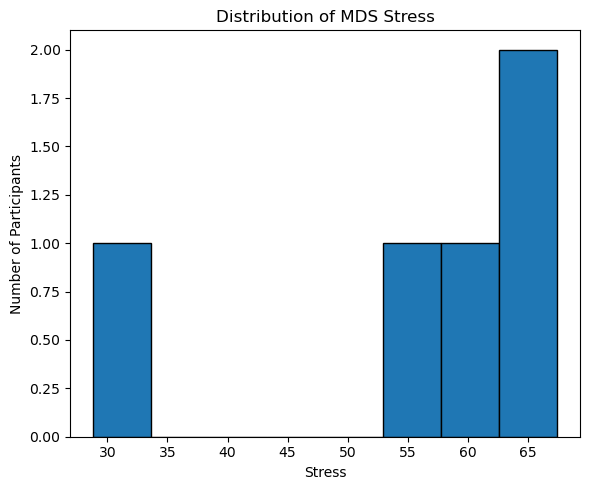

In [15]:
plt.figure(figsize=(6,5))

plt.hist(
    participant_stress,
    bins=8,
    edgecolor="black"
)

plt.xlabel("Stress")

plt.ylabel("Number of Participants")

plt.title("Distribution of MDS Stress")

plt.tight_layout()

plt.show()

In [16]:
group_dissimilarity = 1 - group_similarity

np.fill_diagonal(group_dissimilarity, 0)

In [17]:
group_mds = MDS(
    n_components=2,
    dissimilarity="precomputed",
    random_state=42,
    normalized_stress="auto"
)

group_coords = group_mds.fit_transform(group_dissimilarity)

print("Group Stress:", group_mds.stress_)

Group Stress: 12.533389688933667


/opt/anaconda3/envs/vibrotactile/lib/python3.11/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/opt/anaconda3/envs/vibrotactile/lib/python3.11/site-packages/sklearn/manifold/_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(


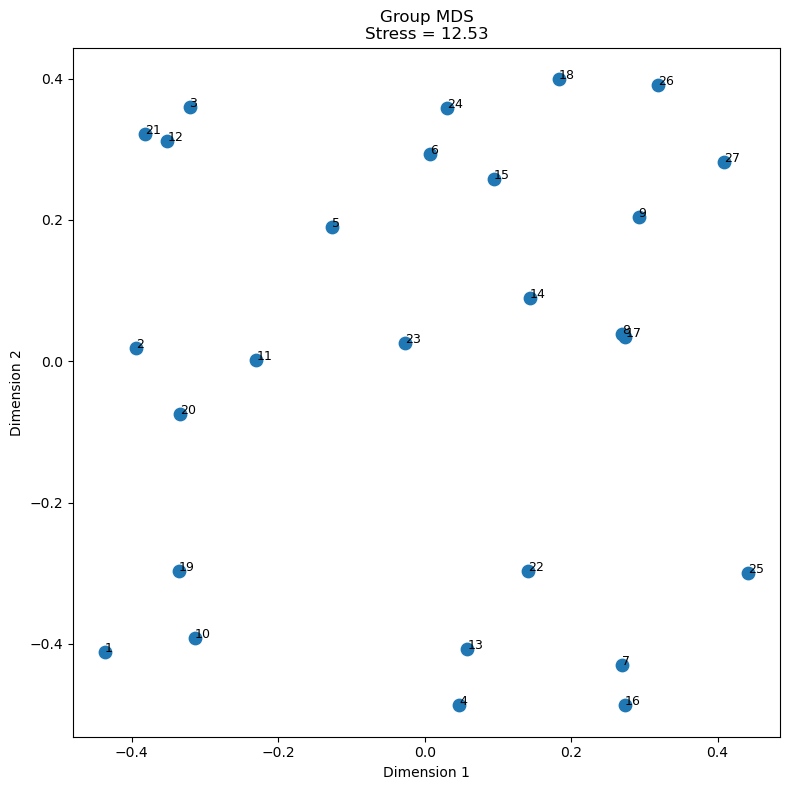

In [18]:
plt.figure(figsize=(8,8))

plt.scatter(
    group_coords[:,0],
    group_coords[:,1],
    s=80
)

for i in range(27):

    plt.text(
        group_coords[i,0],
        group_coords[i,1],
        str(i+1),
        fontsize=9
    )

plt.xlabel("Dimension 1")

plt.ylabel("Dimension 2")

plt.title(
    f"Group MDS\nStress = {group_mds.stress_:.2f}"
)

plt.tight_layout()

plt.show()

In [24]:
stimulus_info = pd.read_csv("../stimuli/attack_27/stimulus_table.csv")

attack = stimulus_info["AttackTime_ms"].values
ifi = stimulus_info["IFI_Hz"].values
am = stimulus_info["AM_Depth"].values

In [25]:
import os
import pandas as pd

stimulus_path = os.path.join(
    "..",
    "stimuli",
    "attack_27",
    "stimulus_table.csv"
)

stimulus_info = pd.read_csv(stimulus_path)

print(stimulus_info.head())

   ID  AttackTime_ms  IFI_Hz     Frequencies  AM_Depth
0   1            100      50  [80, 130, 180]       0.3
1   2            100      50  [80, 130, 180]       0.6
2   3            100      50  [80, 130, 180]       0.9
3   4            100     100  [80, 180, 280]       0.3
4   5            100     100  [80, 180, 280]       0.6


In [26]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

attack_colors = {
    100: "#1f77b4",
    250: "#ff7f0e",
    400: "#2ca02c"
}

ifi_colors = {
    50: "#d62728",
    100: "#9467bd",
    150: "#8c564b"
}

am_colors = {
    0.3: "#17becf",
    0.6: "#bcbd22",
    0.9: "#7f7f7f"
}

In [27]:
def plot_colored_mds(ax, coords, values, color_dict, title):

    for value in sorted(color_dict.keys()):

        idx = values == value

        ax.scatter(
            coords[idx,0],
            coords[idx,1],
            s=80,
            color=color_dict[value],
            edgecolor='black',
            label=str(value)
        )

    for i in range(len(coords)):
        ax.text(
            coords[i,0],
            coords[i,1],
            str(i+1),
            fontsize=7,
            ha='center',
            va='center'
        )

    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Dimension 1")
    ax.set_ylabel("Dimension 2")

    ax.legend(fontsize=7)

In [28]:
def plot_plain_mds(ax, coords, title):

    ax.scatter(
        coords[:,0],
        coords[:,1],
        color="black",
        s=80
    )

    for i in range(len(coords)):
        ax.text(
            coords[i,0],
            coords[i,1],
            str(i+1),
            fontsize=7,
            ha='center',
            va='center'
        )

    ax.set_title(title, fontsize=10)

    ax.set_xlabel("Dimension 1")
    ax.set_ylabel("Dimension 2")

In [29]:
all_coords = [group_coords] + participant_coordinates

xmin = min(np.min(c[:,0]) for c in all_coords)
xmax = max(np.max(c[:,0]) for c in all_coords)

ymin = min(np.min(c[:,1]) for c in all_coords)
ymax = max(np.max(c[:,1]) for c in all_coords)

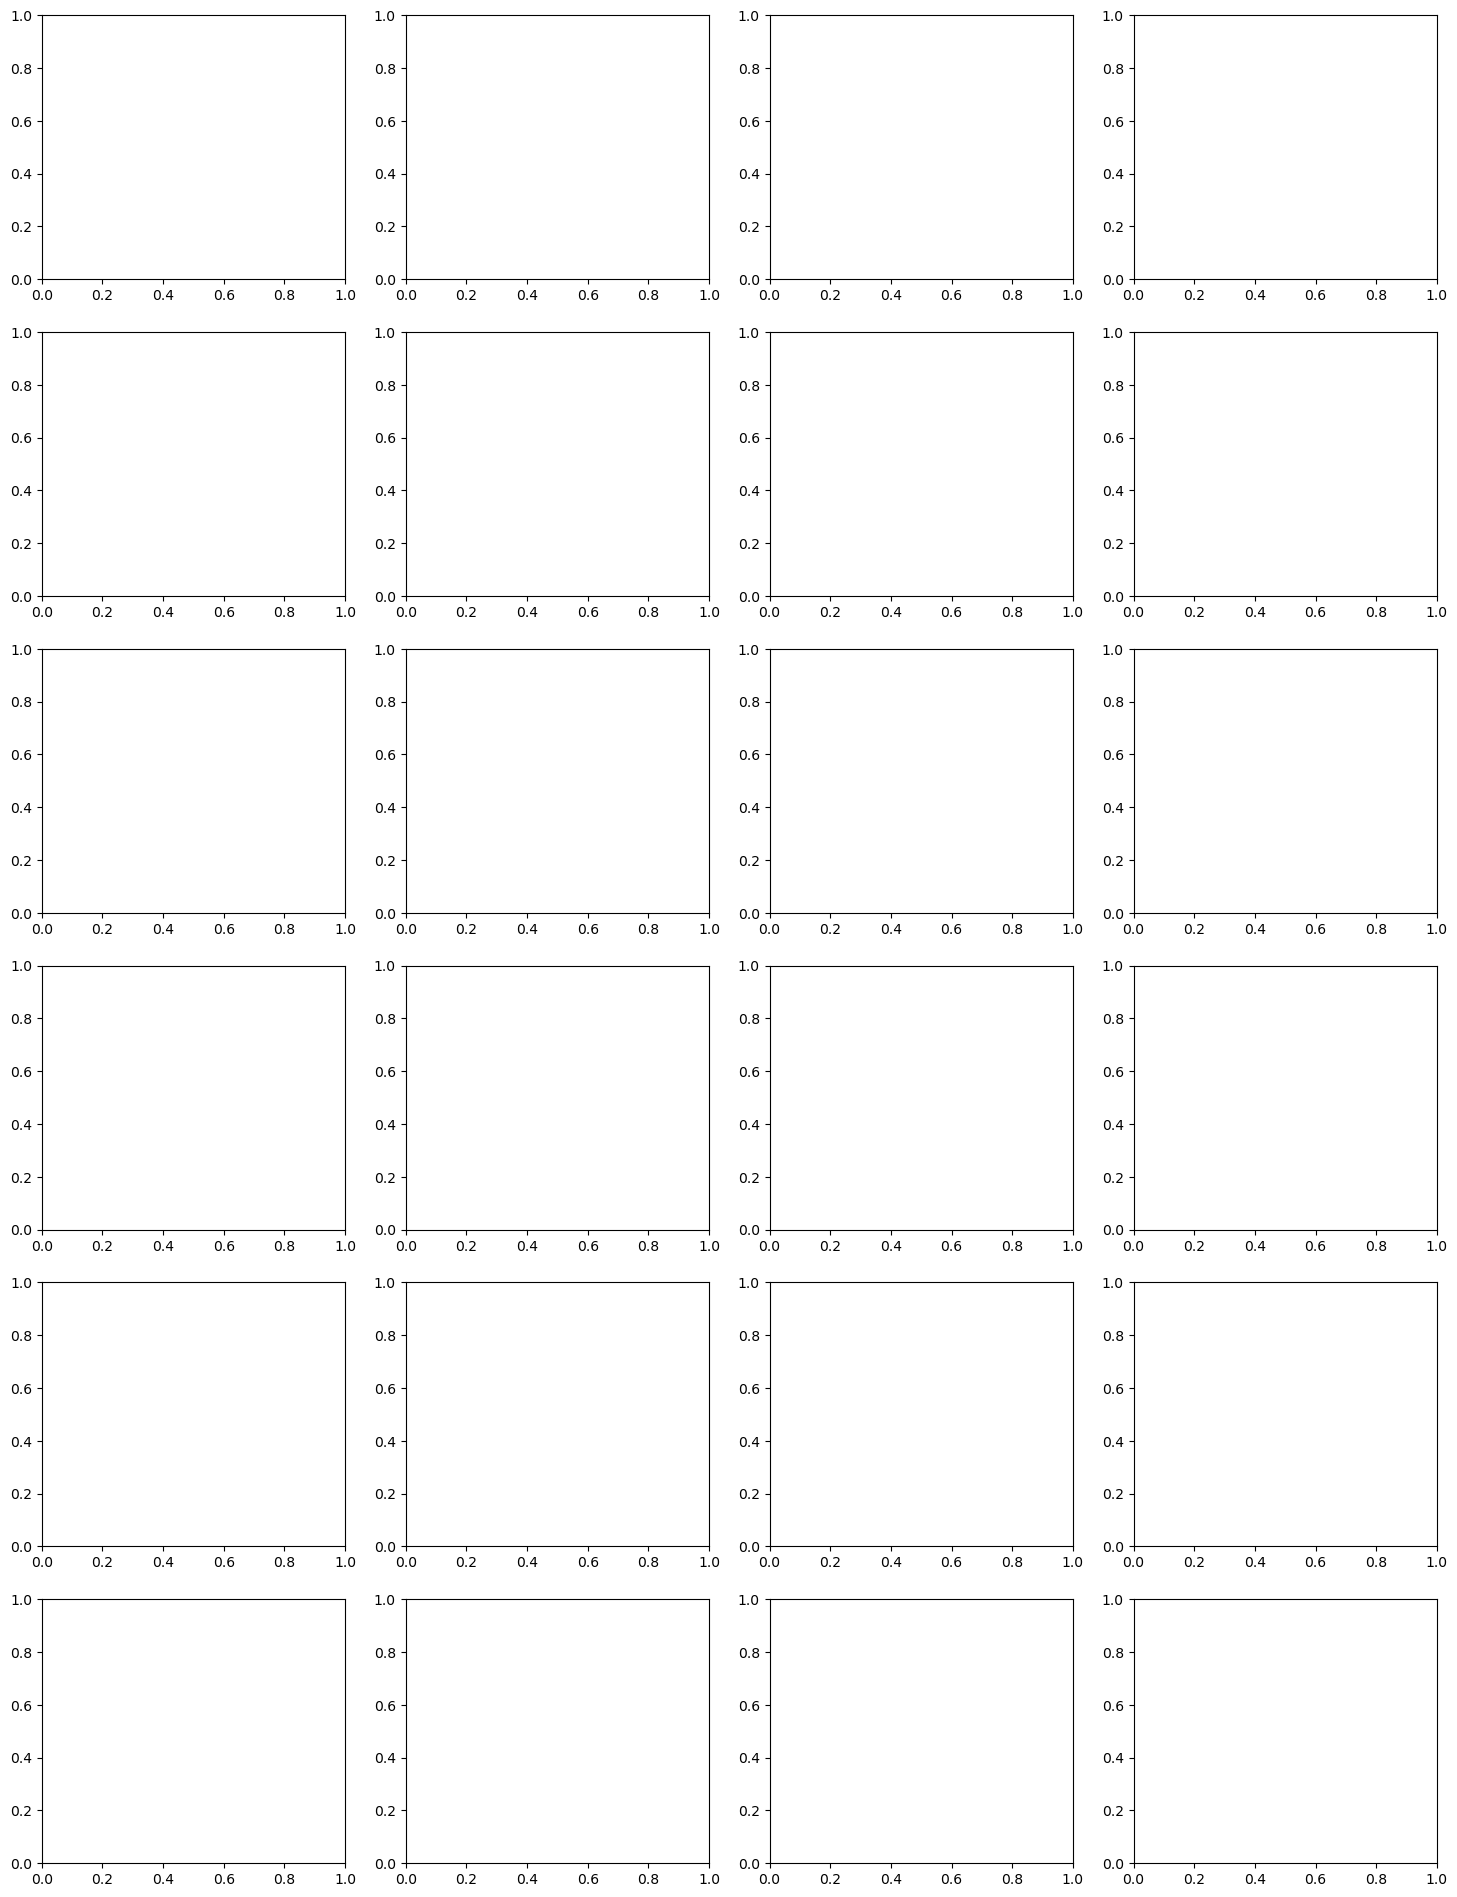

In [30]:
n_participants = len(participant_coordinates)

fig, axes = plt.subplots(
    n_participants + 1,
    4,
    figsize=(18, 4*(n_participants+1))
)

In [31]:
plot_plain_mds(
    axes[0,0],
    group_coords,
    "Group"
)

plot_colored_mds(
    axes[0,1],
    group_coords,
    attack,
    attack_colors,
    "Attack"
)

plot_colored_mds(
    axes[0,2],
    group_coords,
    ifi,
    ifi_colors,
    "IFI"
)

plot_colored_mds(
    axes[0,3],
    group_coords,
    am,
    am_colors,
    "AM"
)

In [32]:
for row, (pid, coords) in enumerate(zip(participant_ids, participant_coordinates), start=1):

    plot_plain_mds(
        axes[row,0],
        coords,
        pid
    )

    plot_colored_mds(
        axes[row,1],
        coords,
        attack,
        attack_colors,
        "Attack"
    )

    plot_colored_mds(
        axes[row,2],
        coords,
        ifi,
        ifi_colors,
        "IFI"
    )

    plot_colored_mds(
        axes[row,3],
        coords,
        am,
        am_colors,
        "AM"
    )

In [33]:
for ax_row in axes:
    for ax in ax_row:
        ax.set_xlim(xmin-0.2, xmax+0.2)
        ax.set_ylim(ymin-0.2, ymax+0.2)

In [34]:
plt.tight_layout()

plt.savefig(
    "All_MDS_Plots.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

<Figure size 640x480 with 0 Axes>

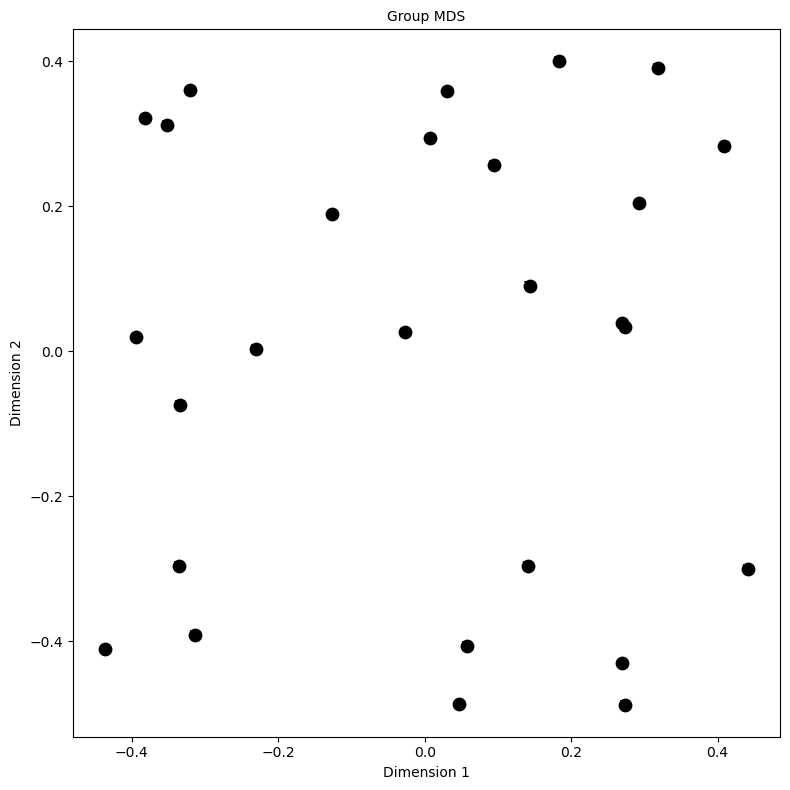

In [35]:
fig, ax = plt.subplots(figsize=(8,8))

plot_plain_mds(ax, group_coords, "Group MDS")

plt.tight_layout()
plt.show()

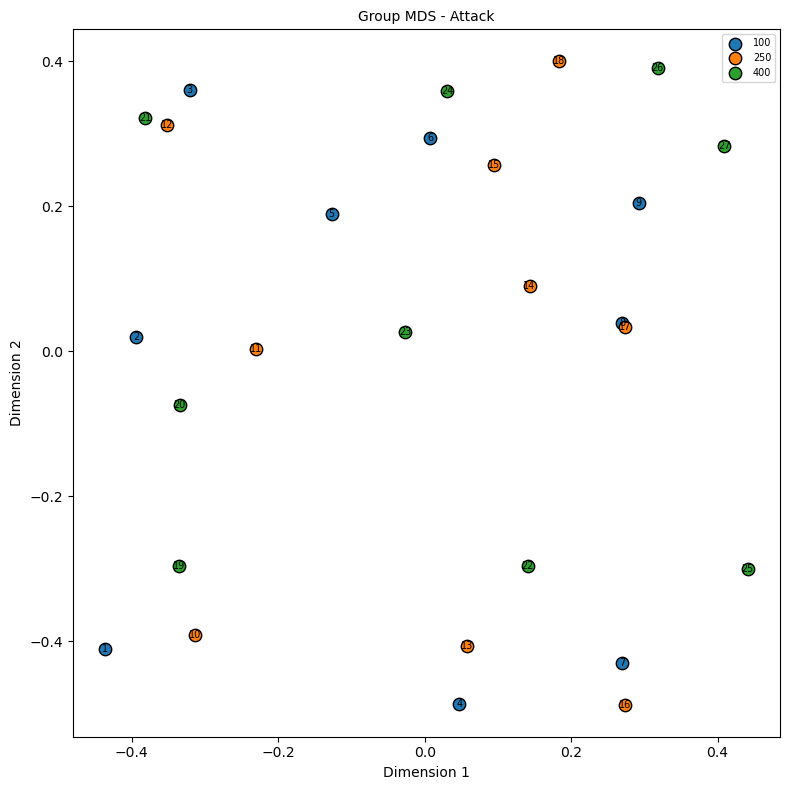

In [36]:
fig, ax = plt.subplots(figsize=(8,8))

plot_colored_mds(
    ax,
    group_coords,
    attack,
    attack_colors,
    "Group MDS - Attack"
)

plt.tight_layout()
plt.show()

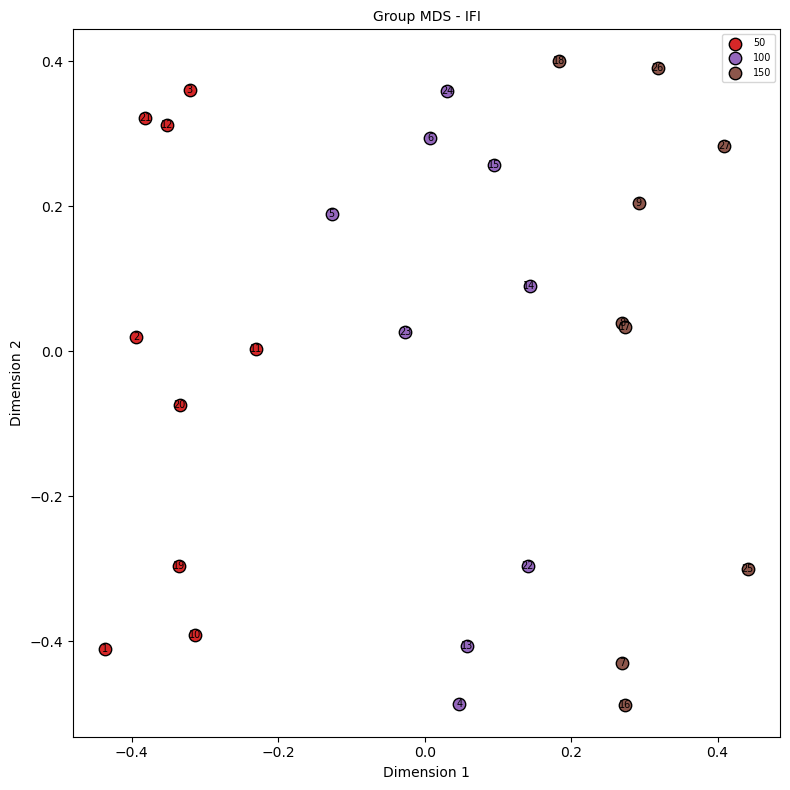

In [37]:
fig, ax = plt.subplots(figsize=(8,8))

plot_colored_mds(
    ax,
    group_coords,
    ifi,
    ifi_colors,
    "Group MDS - IFI"
)

plt.tight_layout()
plt.show()

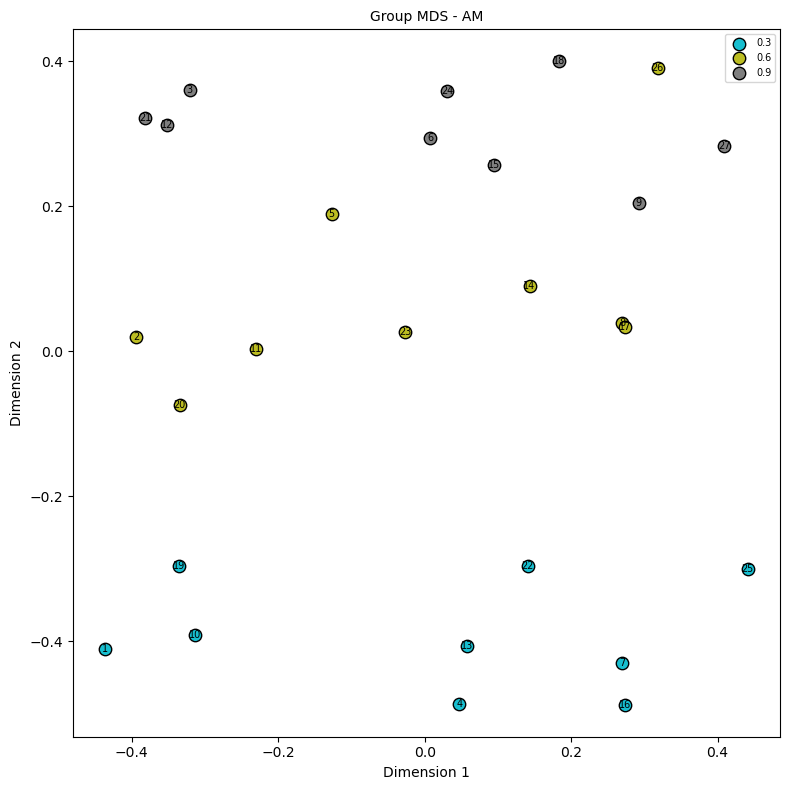

In [38]:
fig, ax = plt.subplots(figsize=(8,8))

plot_colored_mds(
    ax,
    group_coords,
    am,
    am_colors,
    "Group MDS - AM"
)

plt.tight_layout()
plt.show()

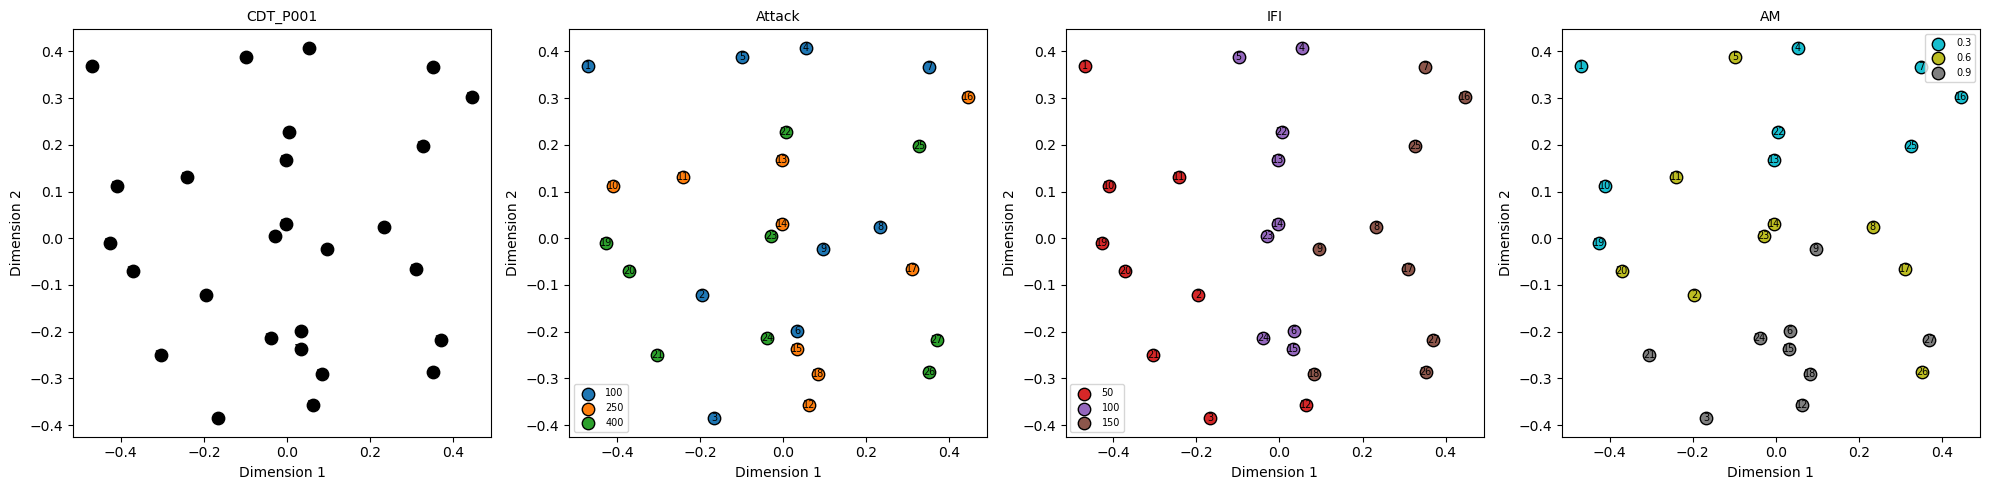

In [39]:
fig, axes = plt.subplots(1,4, figsize=(20,5))

plot_plain_mds(
    axes[0],
    participant_coordinates[0],
    participant_ids[0]
)

plot_colored_mds(
    axes[1],
    participant_coordinates[0],
    attack,
    attack_colors,
    "Attack"
)

plot_colored_mds(
    axes[2],
    participant_coordinates[0],
    ifi,
    ifi_colors,
    "IFI"
)

plot_colored_mds(
    axes[3],
    participant_coordinates[0],
    am,
    am_colors,
    "AM"
)

plt.tight_layout()
plt.show()

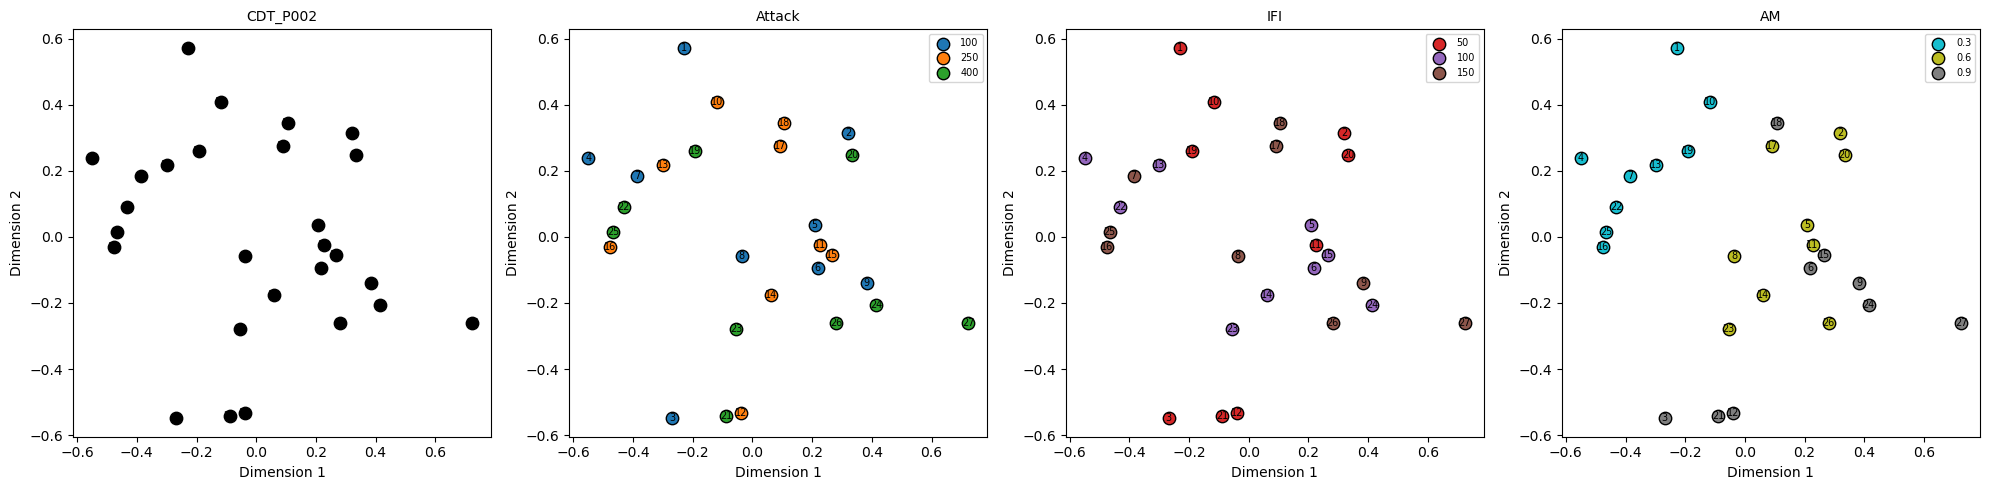

In [40]:
fig, axes = plt.subplots(1,4, figsize=(20,5))

plot_plain_mds(
    axes[0],
    participant_coordinates[1],
    participant_ids[1]
)

plot_colored_mds(
    axes[1],
    participant_coordinates[1],
    attack,
    attack_colors,
    "Attack"
)

plot_colored_mds(
    axes[2],
    participant_coordinates[1],
    ifi,
    ifi_colors,
    "IFI"
)

plot_colored_mds(
    axes[3],
    participant_coordinates[1],
    am,
    am_colors,
    "AM"
)

plt.tight_layout()
plt.show()

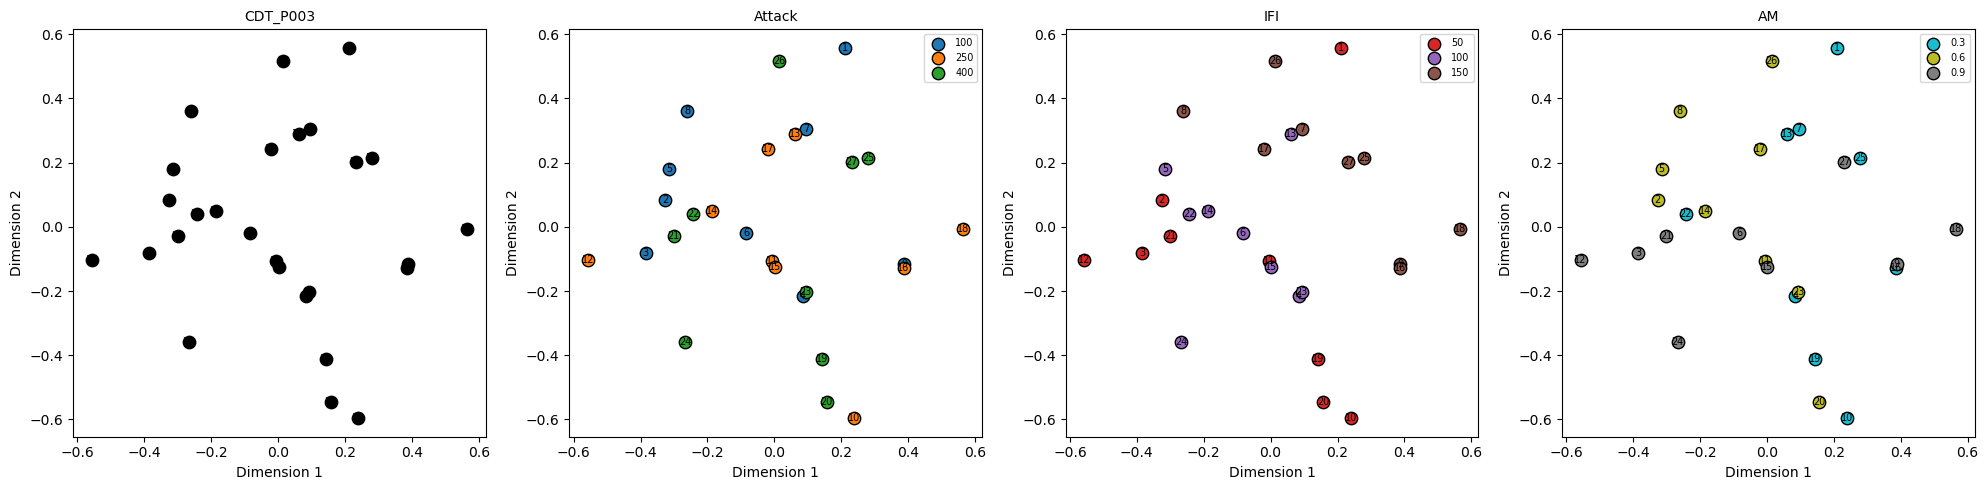

In [41]:
fig, axes = plt.subplots(1,4, figsize=(20,5))

plot_plain_mds(
    axes[0],
    participant_coordinates[2],
    participant_ids[2]
)

plot_colored_mds(
    axes[1],
    participant_coordinates[2],
    attack,
    attack_colors,
    "Attack"
)

plot_colored_mds(
    axes[2],
    participant_coordinates[2],
    ifi,
    ifi_colors,
    "IFI"
)

plot_colored_mds(
    axes[3],
    participant_coordinates[2],
    am,
    am_colors,
    "AM"
)

plt.tight_layout()
plt.show()

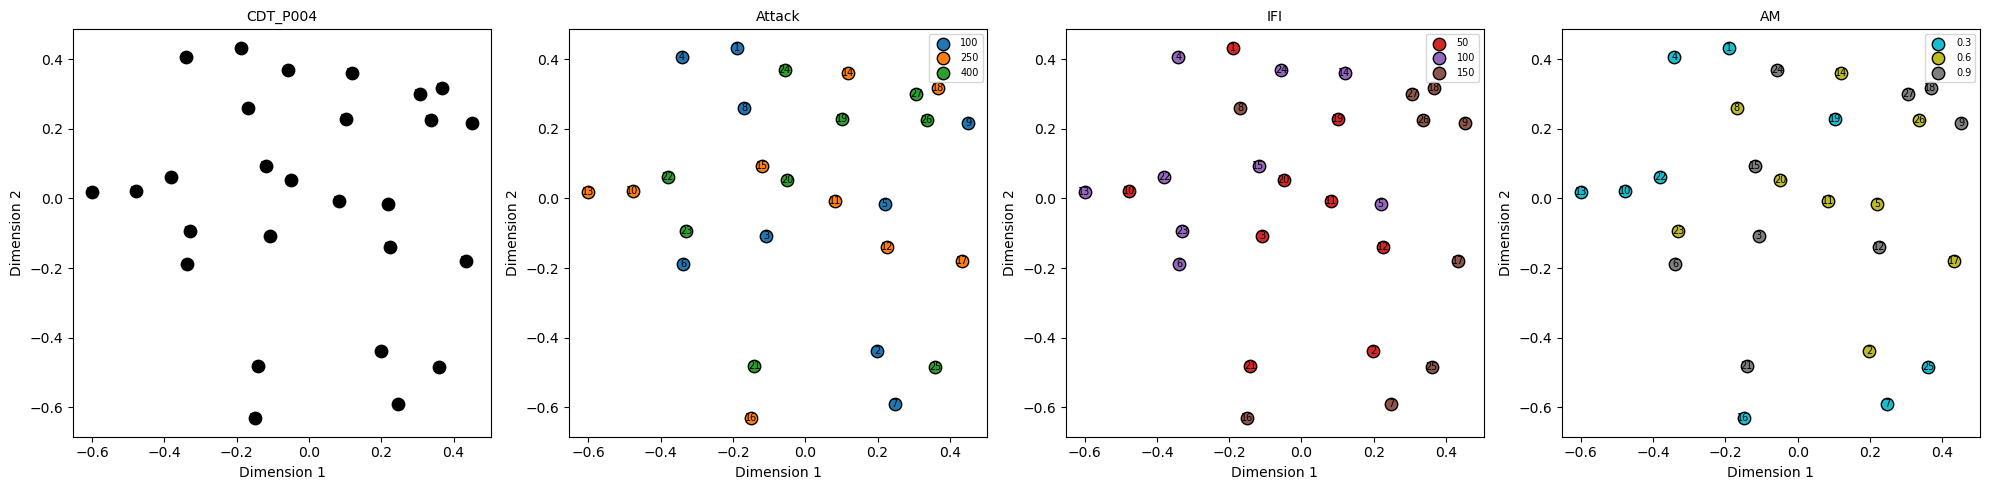

In [42]:
fig, axes = plt.subplots(1,4, figsize=(20,5))

plot_plain_mds(
    axes[0],
    participant_coordinates[3],
    participant_ids[3]
)

plot_colored_mds(
    axes[1],
    participant_coordinates[3],
    attack,
    attack_colors,
    "Attack"
)

plot_colored_mds(
    axes[2],
    participant_coordinates[3],
    ifi,
    ifi_colors,
    "IFI"
)

plot_colored_mds(
    axes[3],
    participant_coordinates[3],
    am,
    am_colors,
    "AM"
)

plt.tight_layout()
plt.show()

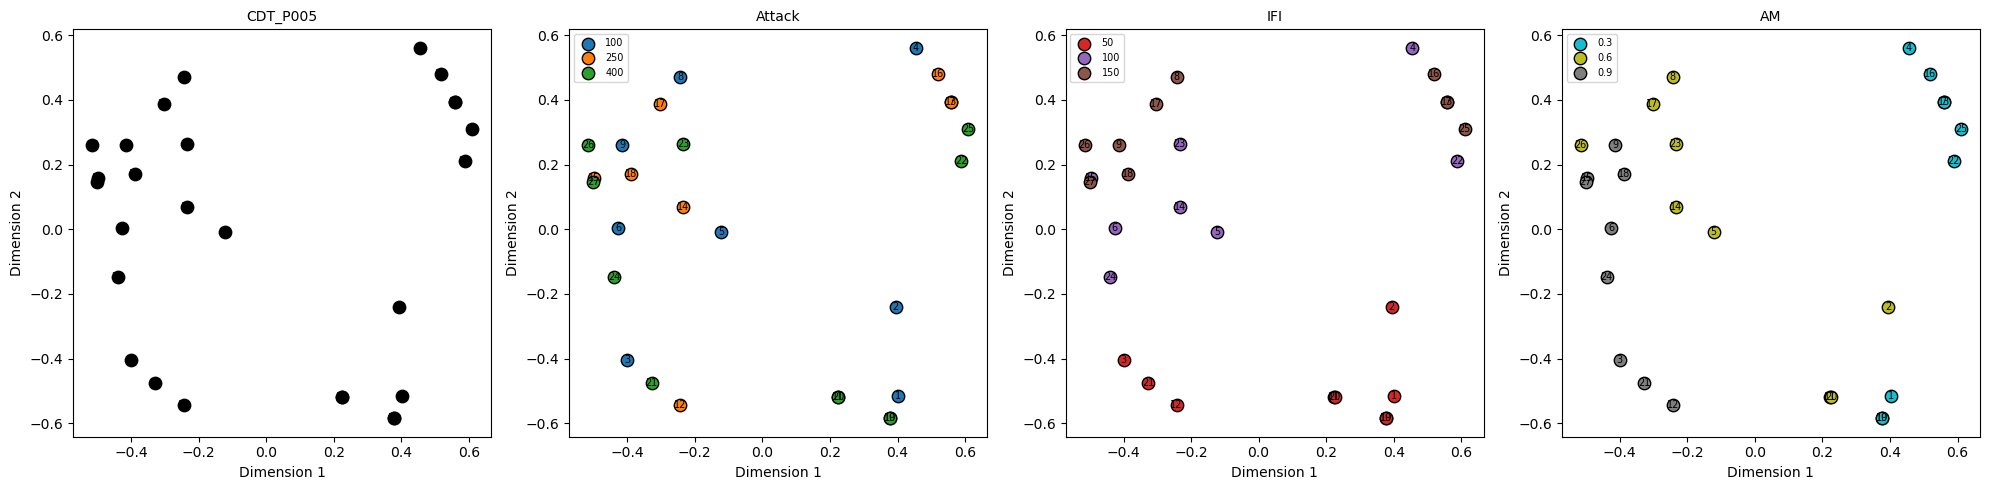

In [43]:
fig, axes = plt.subplots(1,4, figsize=(20,5))

plot_plain_mds(
    axes[0],
    participant_coordinates[4],
    participant_ids[4]
)

plot_colored_mds(
    axes[1],
    participant_coordinates[4],
    attack,
    attack_colors,
    "Attack"
)

plot_colored_mds(
    axes[2],
    participant_coordinates[4],
    ifi,
    ifi_colors,
    "IFI"
)

plot_colored_mds(
    axes[3],
    participant_coordinates[4],
    am,
    am_colors,
    "AM"
)

plt.tight_layout()
plt.show()

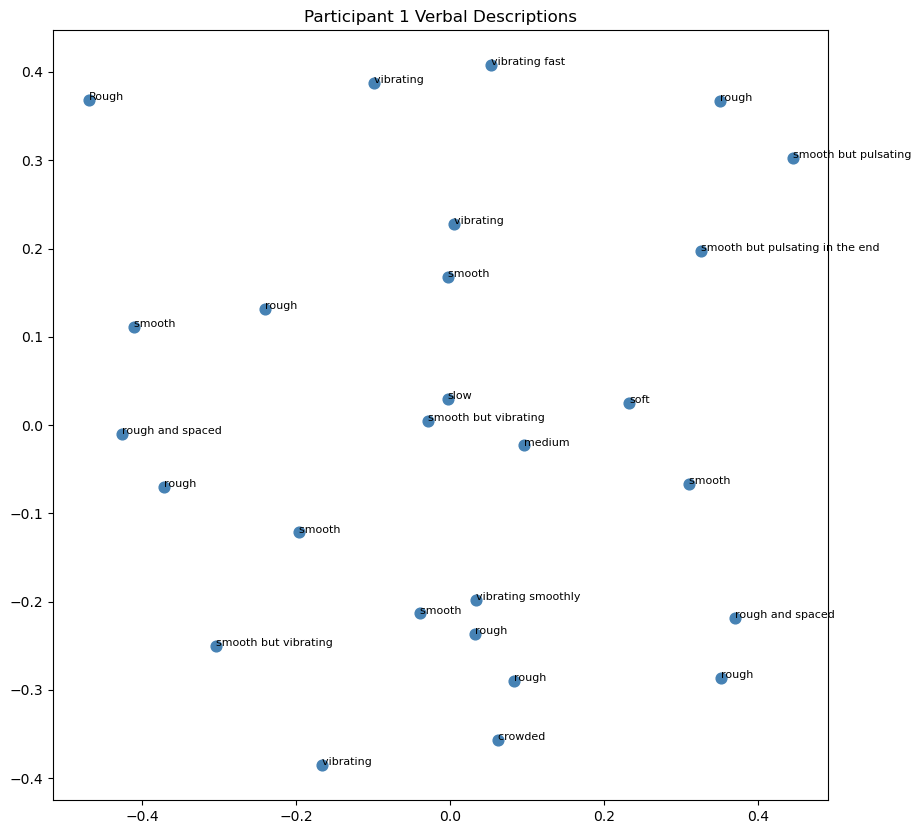

In [44]:
vd = pd.read_csv("../results/CDT_P001/CDT_P001_VD.csv")

labels = vd["Description"].astype(str).values

fig, ax = plt.subplots(figsize=(10,10))

ax.scatter(
    participant_coordinates[0][:,0],
    participant_coordinates[0][:,1],
    s=60,
    color="steelblue"
)

for i, txt in enumerate(labels):

    ax.text(
        participant_coordinates[0][i,0],
        participant_coordinates[0][i,1],
        txt,
        fontsize=8
    )

plt.title("Participant 1 Verbal Descriptions")
plt.show()

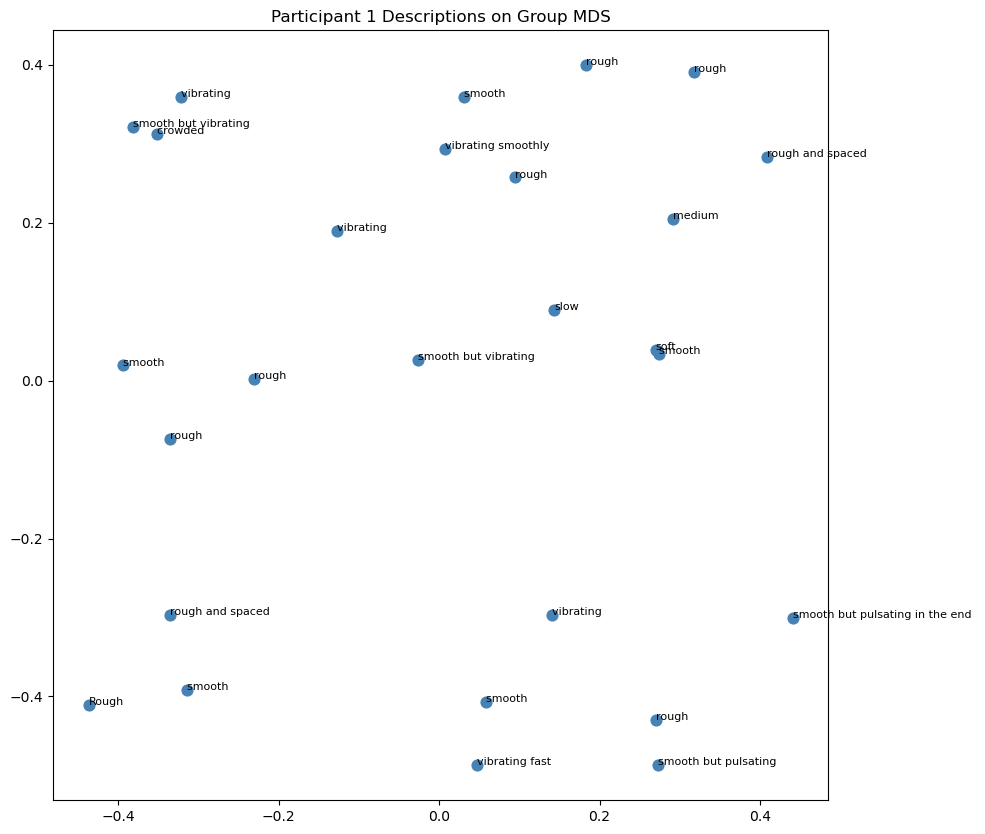

In [45]:
fig, ax = plt.subplots(figsize=(10,10))

ax.scatter(
    group_coords[:,0],
    group_coords[:,1],
    s=60,
    color="steelblue"
)

for i, txt in enumerate(labels):

    ax.text(
        group_coords[i,0],
        group_coords[i,1],
        txt,
        fontsize=8
    )

plt.title("Participant 1 Descriptions on Group MDS")
plt.show()

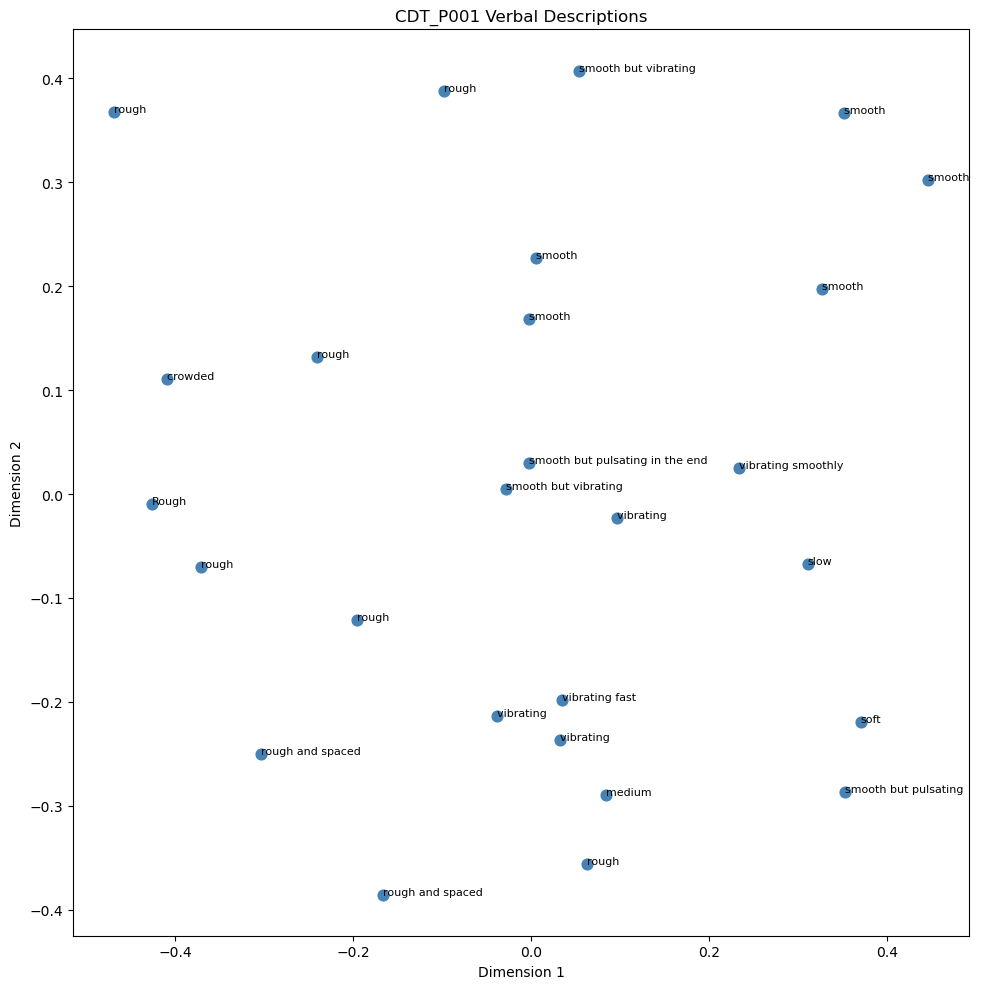

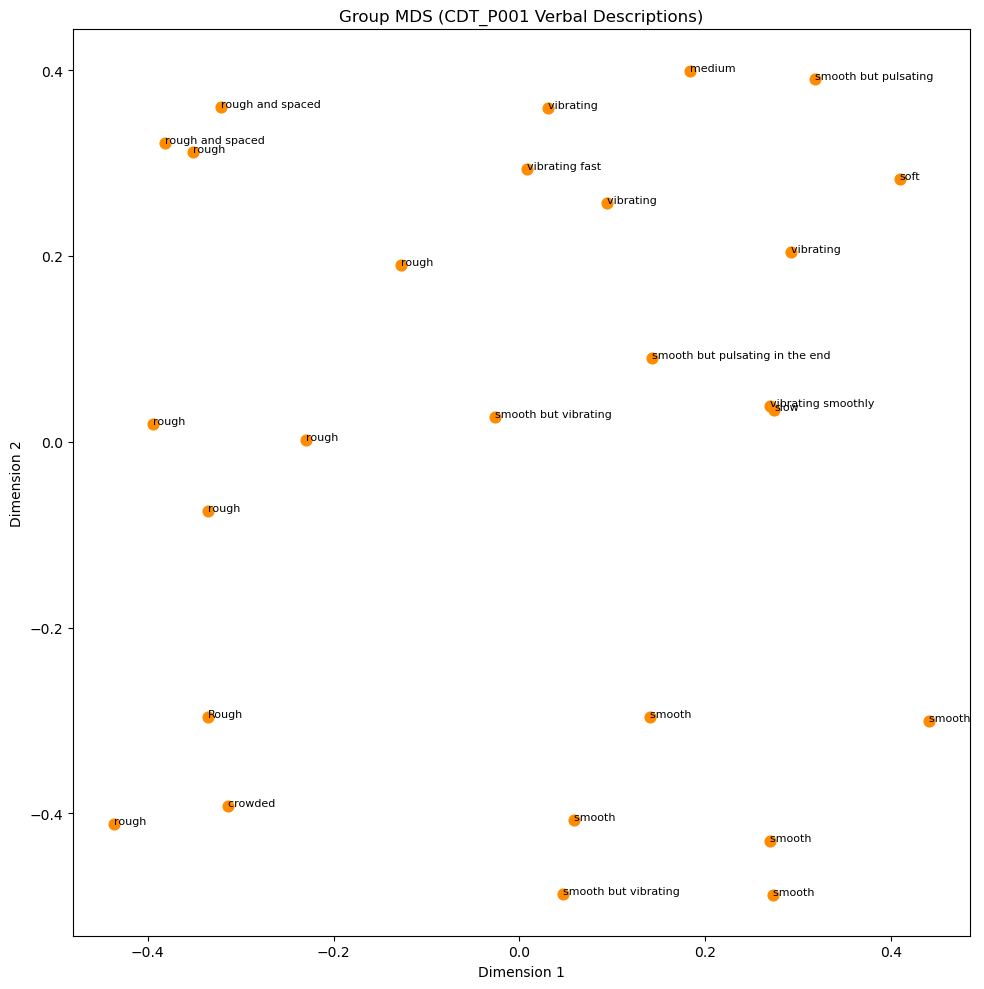

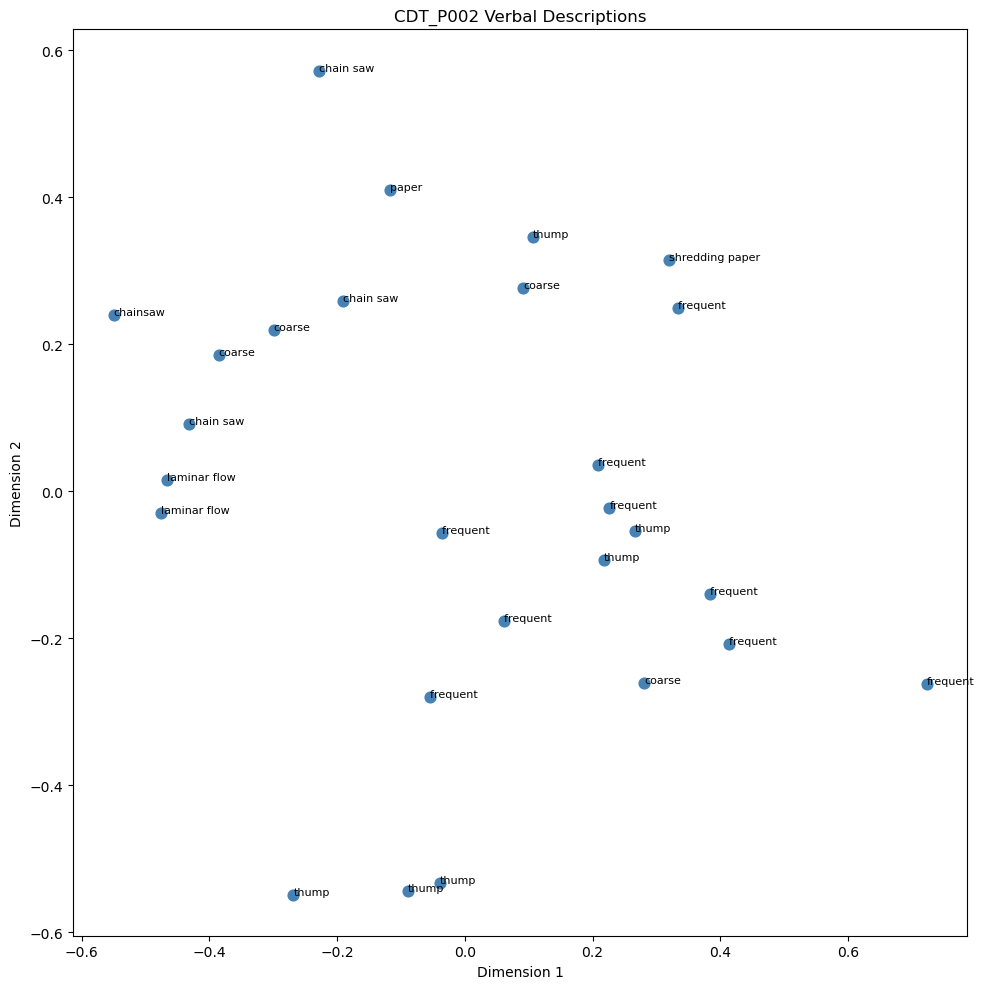

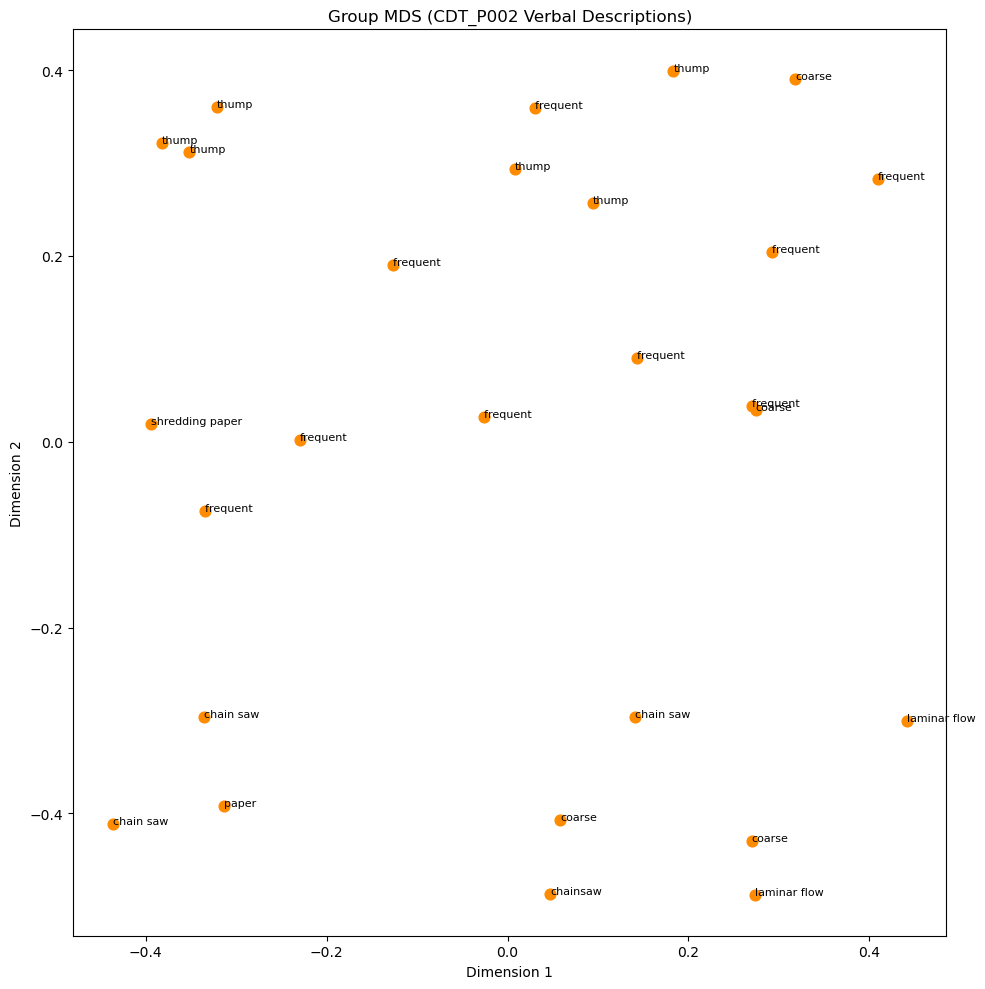

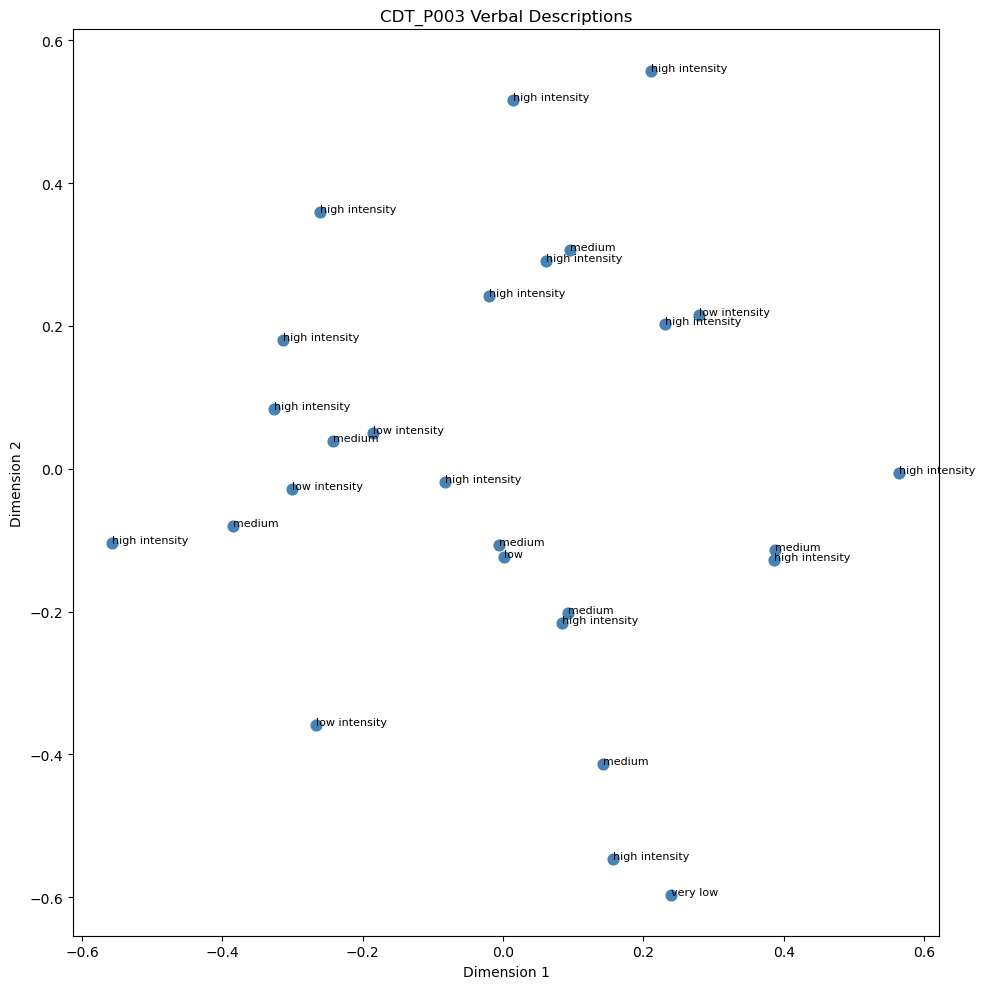

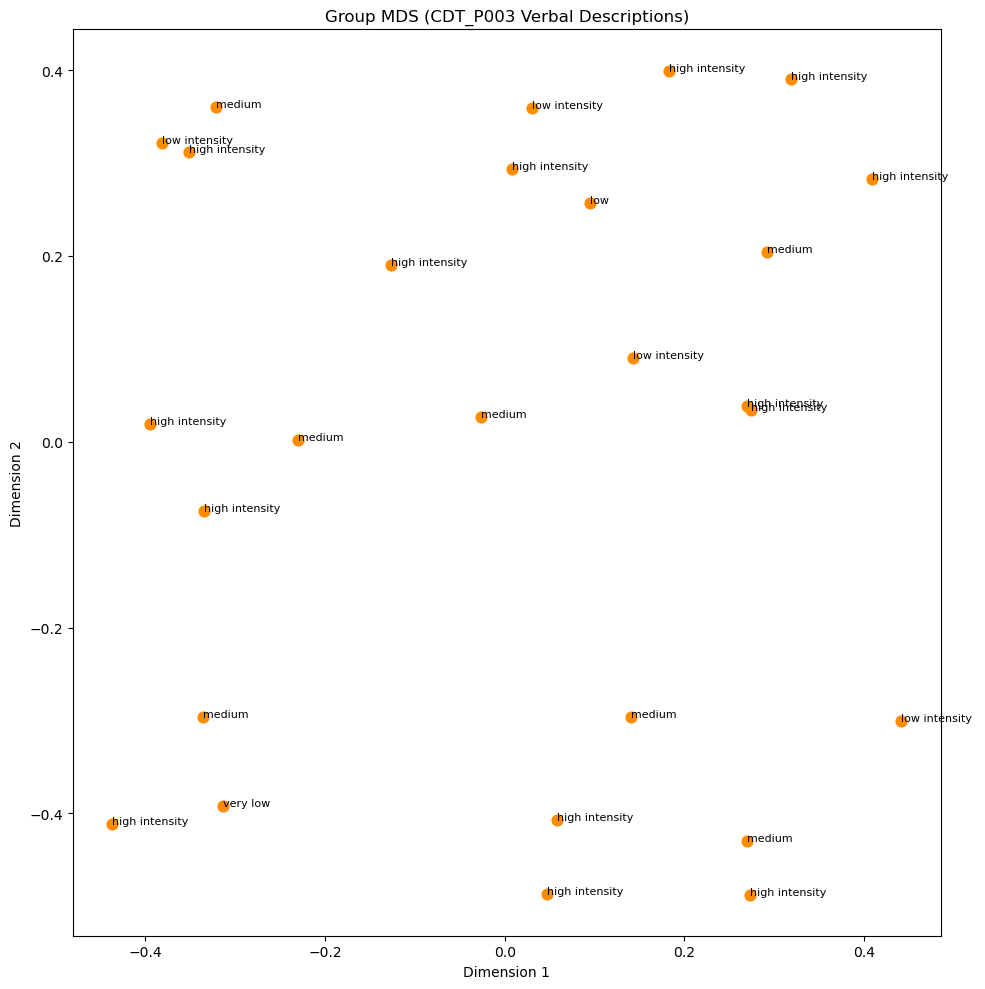

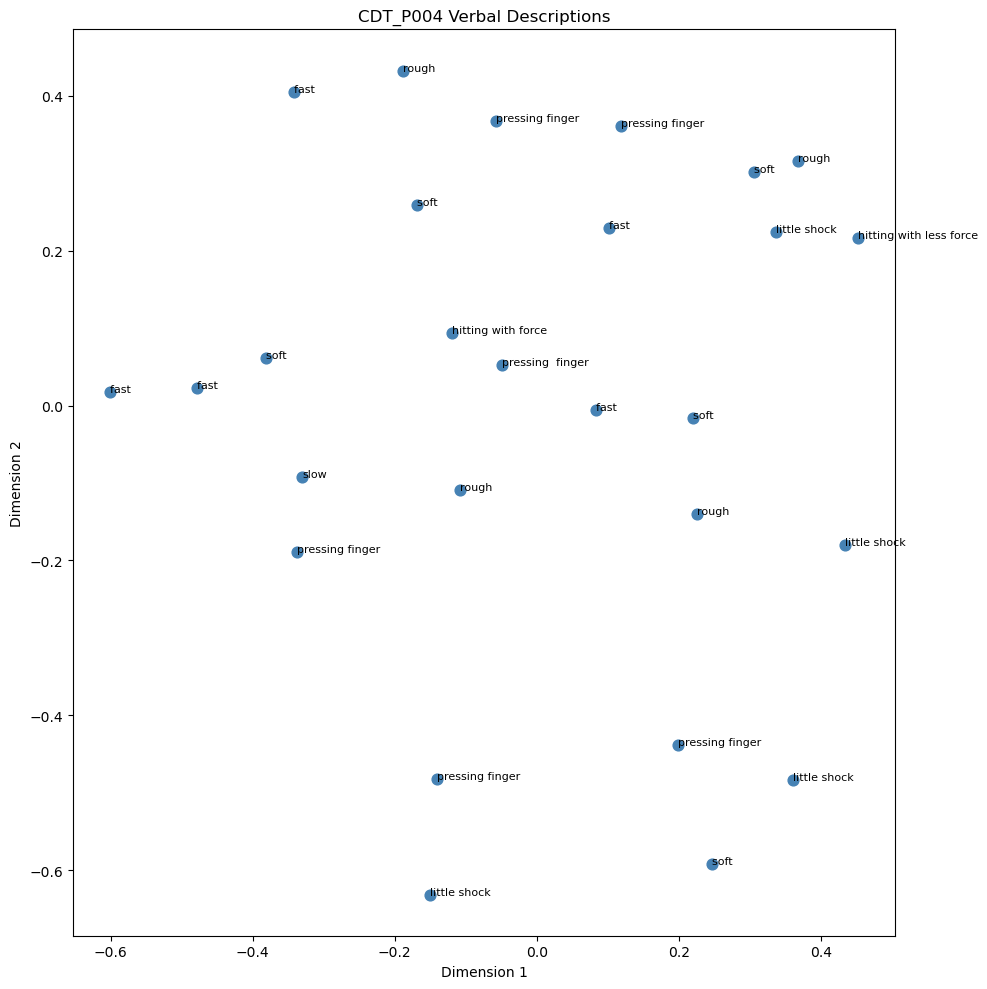

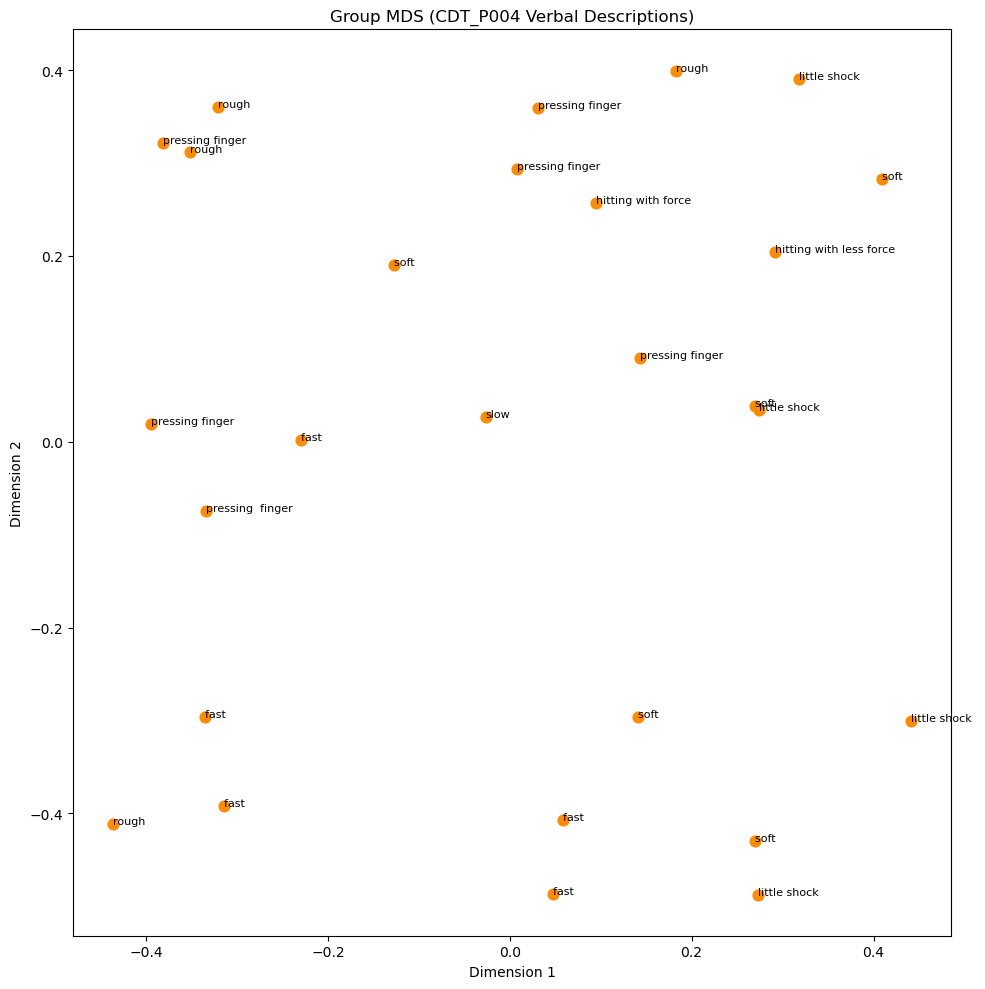

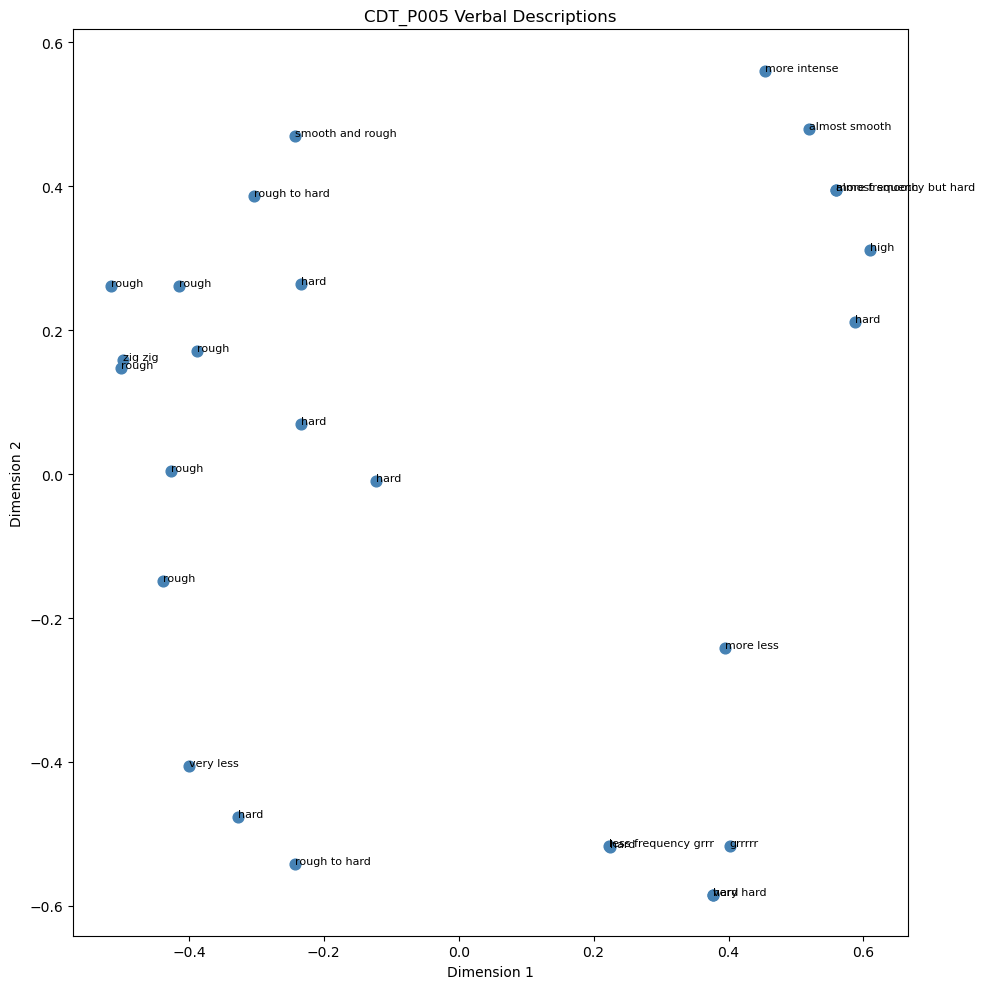

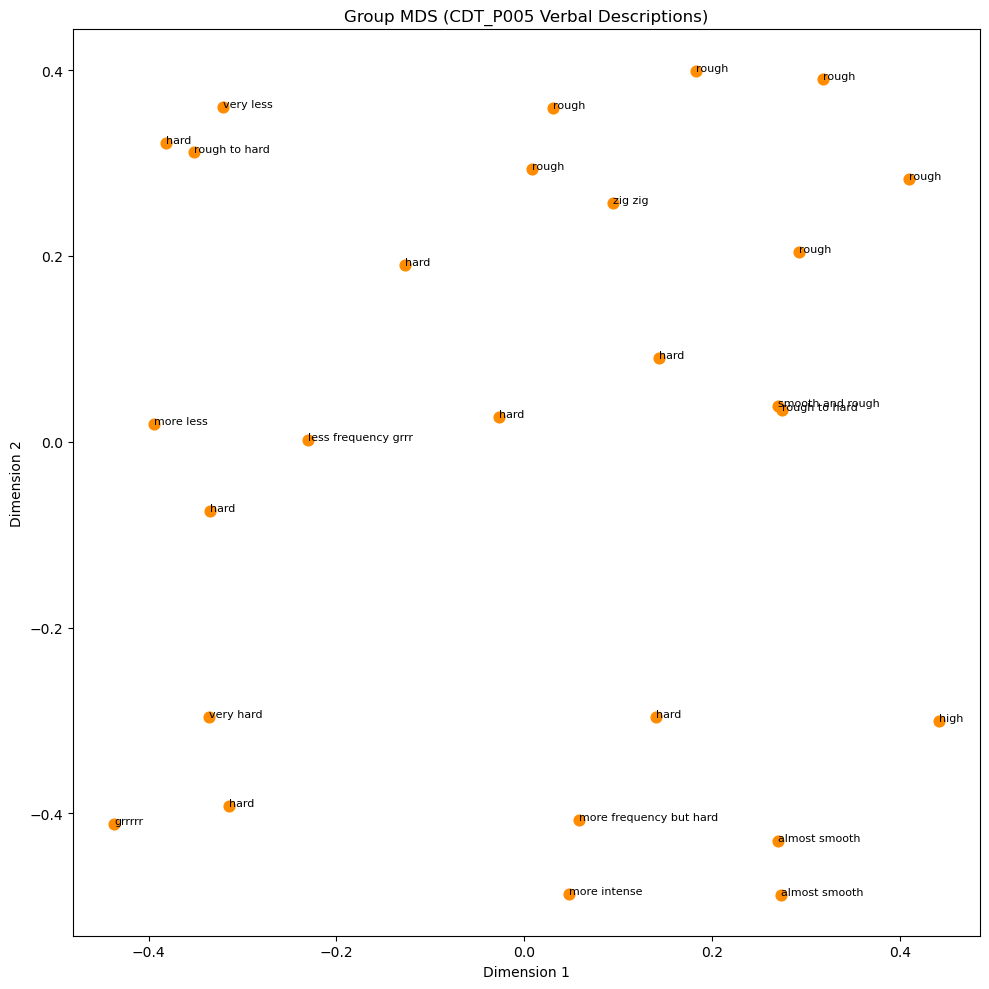

In [46]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt

# Folder containing participant result folders
results_folder = "../results"

# Folder to save figures
save_folder = "Verbal_Description_MDS"
os.makedirs(save_folder, exist_ok=True)

for i, pid in enumerate(participant_ids):

    # ----------------------------
    # Load verbal descriptions
    # ----------------------------
    vd_path = os.path.join(results_folder,
                           pid,
                           f"{pid}_VD.csv")

    vd = pd.read_csv(vd_path)

    # Extract stimulus number from filename
    vd["Stimulus"] = vd["Stimulus_File"].str.extract(r"S(\d+)").astype(int)

    # Sort into S01-S27 order
    vd = vd.sort_values("Stimulus")

    labels = vd["Description"].fillna("").astype(str).values

    # =====================================================
    # Plot 1 : Participant's own MDS
    # =====================================================

    fig, ax = plt.subplots(figsize=(10,10))

    ax.scatter(
        participant_coordinates[i][:,0],
        participant_coordinates[i][:,1],
        s=60,
        color="steelblue"
    )

    for j in range(27):

        ax.text(
            participant_coordinates[i][j,0],
            participant_coordinates[i][j,1],
            labels[j],
            fontsize=8
        )

    ax.set_title(f"{pid} Verbal Descriptions")
    ax.set_xlabel("Dimension 1")
    ax.set_ylabel("Dimension 2")

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            save_folder,
            f"{pid}_OwnMDS_Verbal.png"
        ),
        dpi=300
    )

    plt.show()

    # =====================================================
    # Plot 2 : Group MDS with this participant's labels
    # =====================================================

    fig, ax = plt.subplots(figsize=(10,10))

    ax.scatter(
        group_coords[:,0],
        group_coords[:,1],
        s=60,
        color="darkorange"
    )

    for j in range(27):

        ax.text(
            group_coords[j,0],
            group_coords[j,1],
            labels[j],
            fontsize=8
        )

    ax.set_title(f"Group MDS ({pid} Verbal Descriptions)")
    ax.set_xlabel("Dimension 1")
    ax.set_ylabel("Dimension 2")

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            save_folder,
            f"{pid}_GroupMDS_Verbal.png"
        ),
        dpi=300
    )

    plt.show()

In [47]:
print(f"2D Group Stress = {group_mds.stress_:.4f}")

2D Group Stress = 12.5334


In [48]:
from sklearn.manifold import MDS

stress_values = []

for dim in range(1, 6):

    mds = MDS(
        n_components=dim,
        dissimilarity="precomputed",
        random_state=42,
        normalized_stress="auto"
    )

    mds.fit(group_dissimilarity)

    stress_values.append(mds.stress_)

stress_df = pd.DataFrame({
    "Dimensions": range(1,6),
    "Stress": stress_values
})

print(stress_df)

   Dimensions     Stress
0           1  46.178981
1           2  12.533390
2           3  10.375042
3           4   9.559766
4           5   9.289024


/opt/anaconda3/envs/vibrotactile/lib/python3.11/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/opt/anaconda3/envs/vibrotactile/lib/python3.11/site-packages/sklearn/manifold/_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(
/opt/anaconda3/envs/vibrotactile/lib/python3.11/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/opt/anaconda3/envs/vibrotactile/lib/python3.11/site-packages/sklearn/manifold/_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(
/opt/anaconda3/envs/vibrotactile/lib/p

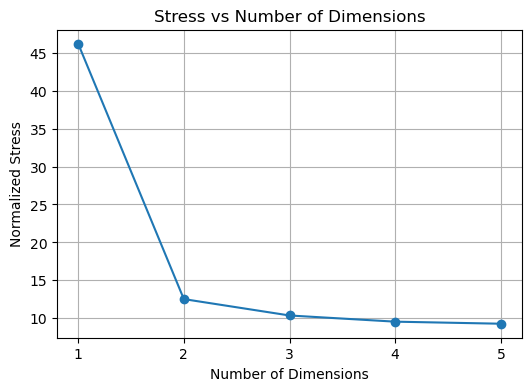

In [49]:
plt.figure(figsize=(6,4))

plt.plot(
    stress_df["Dimensions"],
    stress_df["Stress"],
    marker='o'
)

plt.xticks(range(1,6))

plt.xlabel("Number of Dimensions")
plt.ylabel("Normalized Stress")
plt.title("Stress vs Number of Dimensions")

plt.grid(True)

plt.show()